<a href="https://colab.research.google.com/github/24shinganjuden-lang/DL_CapstoneProject/blob/main/NEU_Defect_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Steel Surface Defect Classification (NEU-DET)
**Deep Learning Lab – Capstone Project | Ramdeobaba University, Nagpur**

Baseline CNN vs MobileNetV3Small (transfer learning) on 6 defect classes.

Before running: `Runtime > Change runtime type > T4 GPU`, then run cells top to bottom.

## 1. Setup

In [ ]:
!pip install -q kagglehub gradio

import os, glob, random, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE = (224, 224)
BATCH = 32
CLASSES = ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
print(tf.__version__, tf.config.list_physical_devices('GPU'))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load dataset
Downloads NEU surface defect database from Kaggle. If the download fails, upload the dataset zip to Colab (left panel > Files), unzip it, and set `DATA_DIR` to that folder.

In [ ]:
import kagglehub
try:
    DATA_DIR = kagglehub.dataset_download("kaustubhdikshit/neu-surface-defect-database")
except Exception as e:
    print("Download failed:", e)
    DATA_DIR = "/content/neu"   # change this if you upload manually
print("Data folder:", DATA_DIR)

PREFIX = [('crazing','cr_',0), ('inclusion','in_',1), ('patches','pa_',2),
          ('pitted','ps_',3), ('rolled','rs_',4), ('scratches','sc_',5)]

def get_label(path):
    name = os.path.splitext(os.path.basename(path))[0].lower()
    for long, short, idx in PREFIX:
        if name.startswith(long) or name.startswith(short):
            return idx
    return None

exts = ('.bmp', '.jpg', '.jpeg', '.png')
files = [f for f in glob.glob(os.path.join(DATA_DIR, '**', '*'), recursive=True) if f.lower().endswith(exts)]
# the Kaggle set can contain both NEU-CLS and NEU-DET copies of the same images; use only one to avoid duplicates
cls = [f for f in files if 'cls' in f.lower()]
det = [f for f in files if 'det' in f.lower()]
if cls: files = cls
elif det: files = det

paths, labels = [], []
for f in files:
    l = get_label(f)
    if l is not None:
        paths.append(f); labels.append(l)
paths, labels = np.array(paths), np.array(labels)

print("Total images:", len(paths))
print(pd.Series(labels).map(lambda i: CLASSES[i]).value_counts())

Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
Data folder: /kaggle/input/neu-surface-defect-database
Total images: 1800
inclusion          300
scratches          300
pitted_surface     300
patches            300
crazing            300
rolled-in_scale    300
Name: count, dtype: int64


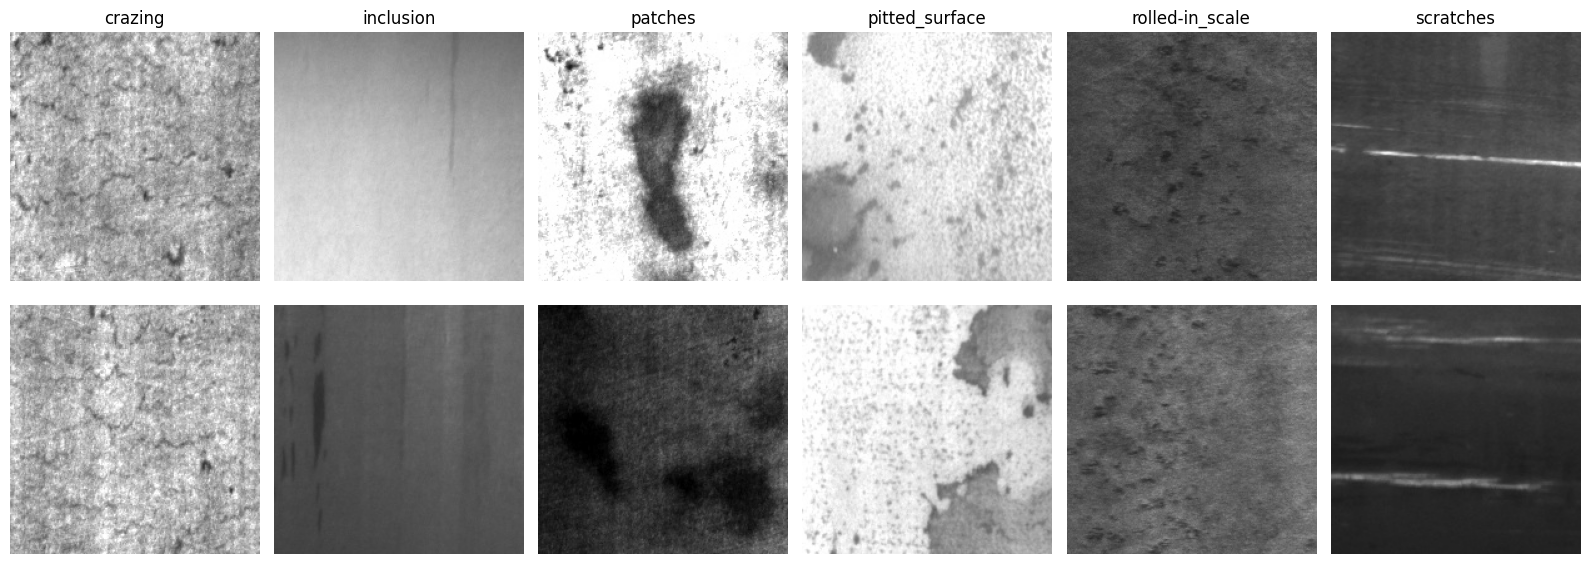

In [ ]:
# sample images
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for c in range(6):
    idx = np.where(labels == c)[0][:2]
    for r, i in enumerate(idx):
        img = keras.utils.load_img(paths[i])
        axes[r, c].imshow(img, cmap='gray'); axes[r, c].axis('off')
        if r == 0: axes[r, c].set_title(CLASSES[c])
plt.tight_layout(); plt.show()

## 3. Split (70 / 15 / 15, stratified) and input pipeline

In [ ]:
p_train, p_tmp, y_train, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_val, p_test, y_val, y_test = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(len(p_train), len(p_val), len(p_test))

def load(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)   # grayscale -> 3 channels
    img = tf.image.resize(img, IMG_SIZE)
    return img, tf.one_hot(label, 6)

def make_ds(p, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if shuffle: ds = ds.shuffle(len(p), seed=SEED)
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(p_train, y_train, True)
val_ds   = make_ds(p_val, y_val)
test_ds  = make_ds(p_test, y_test)

1260 270 270


## 4. Augmentation (training only)

In [ ]:
augment = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomFlip('horizontal'),
    layers.RandomZoom(0.1),
], name='augment')

## 5. Baseline: simple CNN from scratch

In [ ]:
def build_baseline():
    inp = keras.Input((*IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Rescaling(1./255)(x)
    for f in [32, 64, 128]:
        x = layers.Conv2D(f, 3, padding='same', activation='relu')(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(6, activation='softmax')(x)
    return keras.Model(inp, out, name='baseline_cnn')

baseline = build_baseline()
baseline.compile(optimizer=keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,534 (431.77 KB)

 Trainable params: 110,534 (431.77 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cb = [keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True, monitor='val_loss')]
hist_base = baseline.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=cb)

Epoch 1/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 18s 214ms/step - accuracy: 0.1595 - loss: 1.7821 - val_accuracy: 0.1704 - val_loss: 1.7495
Epoch 2/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 95ms/step - accuracy: 0.2262 - loss: 1.7068 - val_accuracy: 0.3407 - val_loss: 1.5559
Epoch 3/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - accuracy: 0.3746 - loss: 1.5377 - val_accuracy: 0.4593 - val_loss: 1.4043
Epoch 4/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.4635 - loss: 1.3729 - val_accuracy: 0.5963 - val_loss: 1.1958
Epoch 5/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - accuracy: 0.5135 - loss: 1.2863 - val_accuracy: 0.5185 - val_loss: 1.1424
Epoch 6/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - accuracy: 0.5310 - loss: 1.2210 - val_accuracy: 0.6222 - val_loss: 1.0201
Epoch 7/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.6135 - loss: 1.0664 - val_accuracy: 0.6407 - val_loss: 1.0287
Epoch 8/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - accuracy: 0.6421 - loss: 0.9899 - val_accuracy: 0.7407 -

## 6. Proposed model: MobileNetV3Small (transfer learning)

In [ ]:
base = keras.applications.MobileNetV3Small(input_shape=(*IMG_SIZE, 3), include_top=False, weights='imagenet')
base.trainable = False

inp = keras.Input((*IMG_SIZE, 3))
x = augment(inp)
x = base(x, training=False)      # MobileNetV3 has its own preprocessing built in (expects 0-255)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(6, activation='softmax')(x)
mnet = keras.Model(inp, out, name='mobilenetv3small_tl')

mnet.compile(optimizer=keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
cb = [keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True, monitor='val_loss')]
hist_tl1 = mnet.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=cb)

4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 92ms/step - accuracy: 0.7984 - loss: 0.7233 - val_accuracy: 0.9852 - val_loss: 0.1437
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.9667 - loss: 0.1582 - val_accuracy: 0.9852 - val_loss: 0.0635
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.9897 - loss: 0.0759 - val_accuracy: 0.9963 - val_loss: 0.0317
Epoch 4/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.9937 - loss: 0.0509 - val_accuracy: 0.9963 - val_loss: 0.0200
Epoch 5/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.9952 - loss: 0.0341 - val_accuracy: 1.0000 - val_loss: 0.0156
Epoch 6/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.9960 - loss: 0.0288 - val_accuracy: 1.0000 - val_loss: 0.0126
Epoch 7/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.9952 - loss: 0.0259 - val_accuracy: 1.0000 - val_loss: 0.0109
Epoch 8/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - accuracy:

In [ ]:
# Fine-tuning: unfreeze the last 30 layers of the backbone with a low learning rate
base.trainable = True
for l in base.layers[:-30]:
    l.trainable = False

mnet.compile(optimizer=keras.optimizers.Adam(1e-4), loss='categorical_crossentropy', metrics=['accuracy'])
cb = [keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True, monitor='val_loss'),
      keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3)]
hist_tl2 = mnet.fit(train_ds, validation_data=val_ds, epochs=25, callbacks=cb)

Epoch 1/25
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 97ms/step - accuracy: 0.8659 - loss: 0.4133 - val_accuracy: 0.9852 - val_loss: 0.0314 - learning_rate: 1.0000e-04
Epoch 2/25
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.9865 - loss: 0.0494 - val_accuracy: 0.9852 - val_loss: 0.0304 - learning_rate: 1.0000e-04
Epoch 3/25
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.9929 - loss: 0.0307 - val_accuracy: 0.9889 - val_loss: 0.0295 - learning_rate: 1.0000e-04
Epoch 4/25
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.9897 - loss: 0.0346 - val_accuracy: 0.9815 - val_loss: 0.0390 - learning_rate: 1.0000e-04
Epoch 5/25
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9952 - loss: 0.0176 - val_accuracy: 0.9852 - val_loss: 0.0393 - learning_rate: 1.0000e-04
Epoch 6/25
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - accuracy: 0.9913 - loss: 0.0207 - val_accuracy: 0.9926 - val_loss: 0.0333 - learning_rate: 1.0000e-04
Epoch 7/25
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.9976

## 7. Training curves

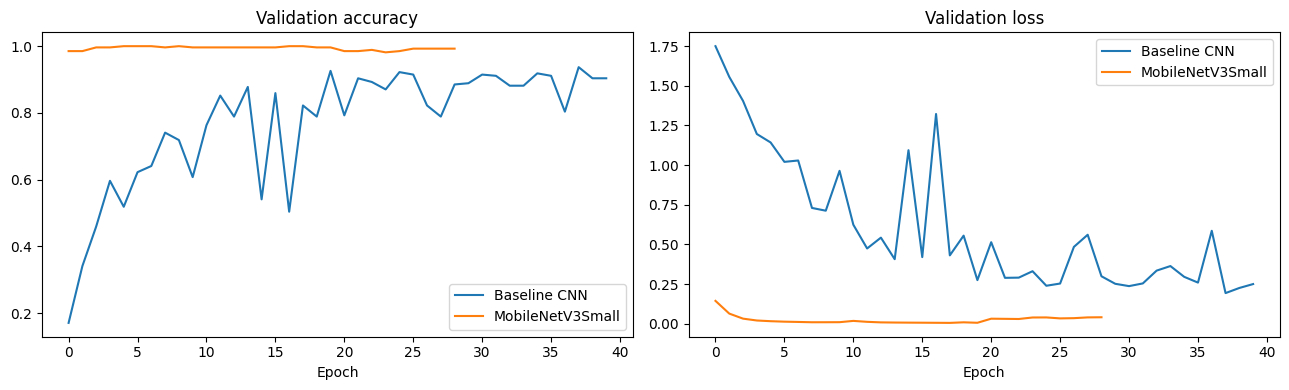

In [ ]:
def merge(*hs):
    out = {}
    for h in hs:
        for k, v in h.history.items(): out.setdefault(k, []).extend(v)
    return out

h_base = merge(hist_base)
h_tl = merge(hist_tl1, hist_tl2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, h in [('Baseline CNN', h_base), ('MobileNetV3Small', h_tl)]:
    ax[0].plot(h['val_accuracy'], label=name)
    ax[1].plot(h['val_loss'], label=name)
ax[0].set_title('Validation accuracy'); ax[1].set_title('Validation loss')
for a in ax: a.set_xlabel('Epoch'); a.legend()
plt.tight_layout(); plt.savefig('training_curves.png', dpi=150); plt.show()

## 8. Evaluation on the test set

===== Baseline_CNN =====
                 precision    recall  f1-score   support

        crazing     0.9000    1.0000    0.9474        45
      inclusion     0.9730    0.8000    0.8780        45
        patches     0.9773    0.9556    0.9663        45
 pitted_surface     0.8095    0.7556    0.7816        45
rolled-in_scale     0.9783    1.0000    0.9890        45
      scratches     0.8824    1.0000    0.9375        45

       accuracy                         0.9185       270
      macro avg     0.9201    0.9185    0.9166       270
   weighted avg     0.9201    0.9185    0.9166       270



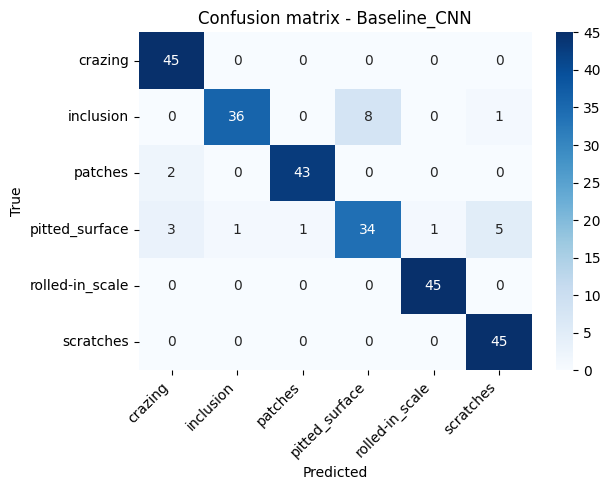

===== MobileNetV3Small =====
                 precision    recall  f1-score   support

        crazing     1.0000    1.0000    1.0000        45
      inclusion     0.9783    1.0000    0.9890        45
        patches     1.0000    1.0000    1.0000        45
 pitted_surface     1.0000    1.0000    1.0000        45
rolled-in_scale     1.0000    1.0000    1.0000        45
      scratches     1.0000    0.9778    0.9888        45

       accuracy                         0.9963       270
      macro avg     0.9964    0.9963    0.9963       270
   weighted avg     0.9964    0.9963    0.9963       270



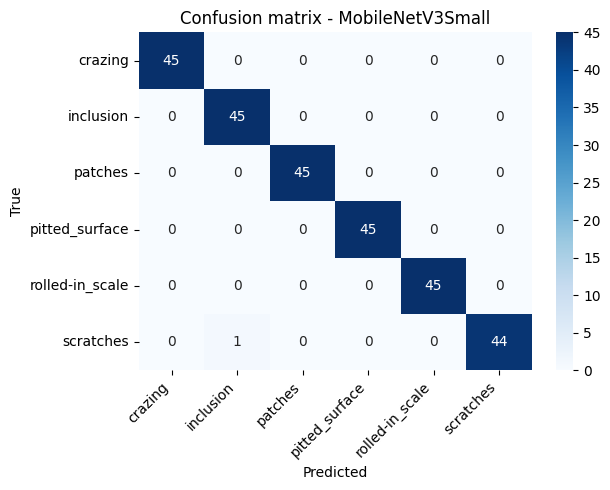

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),Parameters
0,Baseline_CNN,0.9185,0.9201,0.9185,0.9166,110534
1,MobileNetV3Small,0.9963,0.9964,0.9963,0.9963,1013750


In [ ]:
def evaluate(model, name):
    y_true = np.concatenate([np.argmax(y, 1) for _, y in test_ds])
    y_prob = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_prob, 1)
    print(f"===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6.5, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Confusion matrix - {name}')
    plt.xticks(rotation=45, ha='right'); plt.tight_layout()
    plt.savefig(f'cm_{name}.png', dpi=150); plt.show()
    rep = classification_report(y_true, y_pred, output_dict=True)
    return y_true, y_pred, {'Model': name, 'Accuracy': accuracy_score(y_true, y_pred),
                            'Precision (macro)': rep['macro avg']['precision'],
                            'Recall (macro)': rep['macro avg']['recall'],
                            'F1 (macro)': rep['macro avg']['f1-score'],
                            'Parameters': model.count_params()}

_, _, r1 = evaluate(baseline, 'Baseline_CNN')
yt, yp, r2 = evaluate(mnet, 'MobileNetV3Small')

results = pd.DataFrame([r1, r2]).round(4)
results

## 9. Error analysis (misclassified test images)

1 misclassified out of 270


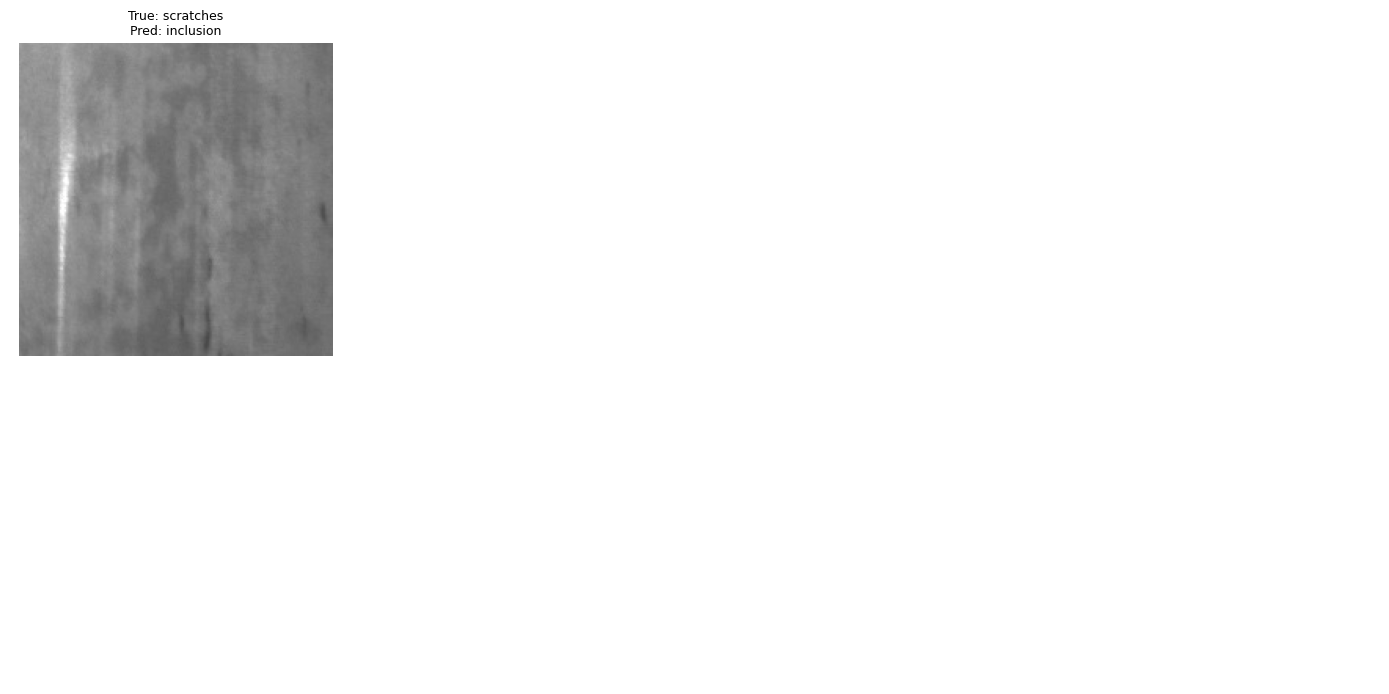

In [ ]:
wrong = np.where(yt != yp)[0]
print(f"{len(wrong)} misclassified out of {len(yt)}")
if len(wrong):
    n = min(8, len(wrong))
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax, i in zip(axes.ravel(), wrong[:n]):
        ax.imshow(keras.utils.load_img(p_test[i]), cmap='gray')
        ax.set_title(f"True: {CLASSES[yt[i]]}\nPred: {CLASSES[yp[i]]}", fontsize=9); ax.axis('off')
    for ax in axes.ravel()[n:]: ax.axis('off')
    plt.tight_layout(); plt.savefig('misclassified.png', dpi=150); plt.show()

## 10. Save models

In [ ]:
mnet.save('mobilenetv3_neu.keras')
baseline.save('baseline_cnn_neu.keras')
results.to_csv('results.csv', index=False)

## 11. Prototype
Upload a steel surface image and get the predicted defect and confidence. A public link is generated, which you can open during the demo.

In [ ]:
import gradio as gr
from PIL import Image

def predict(img):
    img = img.convert('RGB').resize(IMG_SIZE)
    arr = np.expand_dims(np.array(img, dtype='float32'), 0)
    probs = mnet.predict(arr, verbose=0)[0]
    return {CLASSES[i]: float(probs[i]) for i in range(6)}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type='pil', label='Upload steel surface image'),
    outputs=gr.Label(num_top_classes=3, label='Predicted defect'),
    title='Steel Surface Defect Classifier',
    description='MobileNetV3Small (transfer learning) trained on the NEU surface defect database.')
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e7bd8e5ae66b32d149.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
!pip install -q gradio

import numpy as np, gradio as gr
from tensorflow import keras

CLASSES = ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
IMG_SIZE = (224, 224)

mnet = keras.models.load_model('/content/mobilenetv3_neu.keras')

def predict(img):
    img = img.convert('RGB').resize(IMG_SIZE)
    arr = np.expand_dims(np.array(img, dtype='float32'), 0)
    probs = mnet.predict(arr, verbose=0)[0]
    return {CLASSES[i]: float(probs[i]) for i in range(6)}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type='pil', label='Upload steel surface image'),
    outputs=gr.Label(num_top_classes=3, label='Predicted defect'),
    title='Steel Surface Defect Classifier',
    description='MobileNetV3Small (transfer learning) trained on the NEU surface defect database.')
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://85825baa506c845a88.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


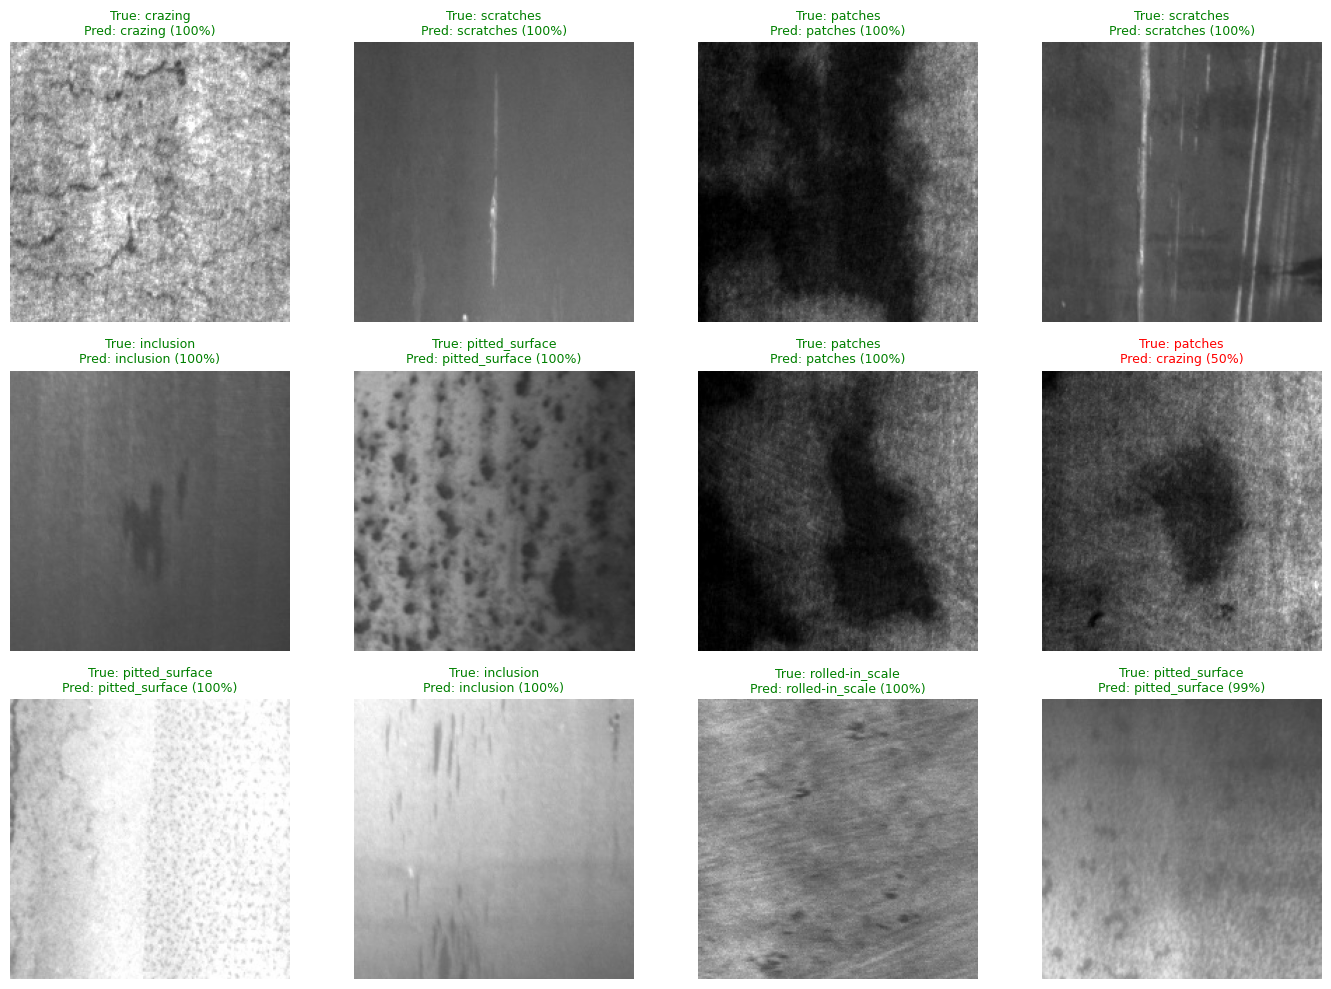

11/12 correct


In [ ]:
idx = np.random.choice(len(p_test), 12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
correct = 0
for ax, i in zip(axes.ravel(), idx):
    img = keras.utils.load_img(p_test[i])
    probs = predict(img)                      # same function the demo uses
    pred = max(probs, key=probs.get)
    true = CLASSES[y_test[i]]
    ok = pred == true; correct += ok
    ax.imshow(img, cmap='gray'); ax.axis('off')
    ax.set_title(f"True: {true}\nPred: {pred} ({probs[pred]*100:.0f}%)",
                 fontsize=9, color='green' if ok else 'red')
plt.tight_layout(); plt.show()
print(f"{correct}/12 correct")

In [ ]:
import shutil
from google.colab import files

os.makedirs('demo_images', exist_ok=True)
for c in range(6):
    sel = [p for p, y in zip(p_test, y_test) if y == c][:3]
    for k, p in enumerate(sel, 1):
        ext = os.path.splitext(p)[1]
        shutil.copy(p, f'demo_images/{CLASSES[c]}_{k}{ext}')

shutil.make_archive('demo_images', 'zip', 'demo_images')
files.download('demo_images.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Package Project for GitHub Export
This section packages your notebook code, outputs, and weights into a clean GitHub repository structure and zips it for download.

In [ ]:
import os
import shutil
from google.colab import files

# Define directory structure
REPO_DIR = 'neu_defect_classification_repo'
os.makedirs(REPO_DIR, exist_ok=True)
os.makedirs(f'{REPO_DIR}/src', exist_ok=True)
os.makedirs(f'{REPO_DIR}/models', exist_ok=True)
os.makedirs(f'{REPO_DIR}/outputs', exist_ok=True)

# 1. Create source code files
src_app_py = """import gradio as gr
import numpy as np
from tensorflow import keras
from PIL import Image

CLASSES = ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
IMG_SIZE = (224, 224)

try:
    mnet = keras.models.load_model('models/mobilenetv3_neu.keras')
except:
    mnet = keras.models.load_model('mobilenetv3_neu.keras')

def predict(img):
    img = img.convert('RGB').resize(IMG_SIZE)
    arr = np.expand_dims(np.array(img, dtype='float32'), 0)
    probs = mnet.predict(arr, verbose=0)[0]
    return {CLASSES[i]: float(probs[i]) for i in range(6)}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type='pil', label='Upload steel surface image'),
    outputs=gr.Label(num_top_classes=3, label='Predicted defect'),
    title='Steel Surface Defect Classifier',
    description='MobileNetV3Small (transfer learning) trained on the NEU surface defect database.')

if __name__ == '__main__':
    demo.launch(share=True)
"""

with open(f'{REPO_DIR}/src/app.py', 'w') as f:
    f.write(src_app_py)

# 2. Copy models if they exist in workspace
for model_name in ['mobilenetv3_neu.keras', 'baseline_cnn_neu.keras']:
    if os.path.exists(model_name):
        shutil.copy(model_name, f'{REPO_DIR}/models/{model_name}')

# 3. Copy generated figures and files
for file_name in ['training_curves.png', 'cm_Baseline_CNN.png', 'cm_MobileNetV3Small.png', 'misclassified.png', 'results.csv']:
    if os.path.exists(file_name):
        shutil.copy(file_name, f'{REPO_DIR}/outputs/{file_name}')

# 4. Generate Requirements file
requirements = """tensorflow>=2.15.0
gradio>=4.0.0
matplotlib>=3.7.0
seaborn>=0.12.0
pandas>=2.0.0
numpy>=1.23.5
scikit-learn>=1.2.0
kagglehub>=0.2.0
"""
with open(f'{REPO_DIR}/requirements.txt', 'w') as f:
    f.write(requirements)

# 5. Generate Markdown README
readme_content = """# Steel Surface Defect Classification (NEU-DET)
An end-to-end Deep Learning project comparing a **Baseline CNN** against **MobileNetV3Small (Transfer Learning + Fine-tuning)** to identify 6 defect types on steel surfaces.

## Project Architecture
- **Baseline CNN**: 3 Convolutional blocks with Global Average Pooling (110,534 parameters).
- **MobileNetV3Small**: Transfer learning + Fine-tuning the top 30 layers on the NEU-DET classification dataset (1,013,750 parameters).

## Dataset
The dataset is based on the **NEU Surface Defect Database** consisting of 1,800 images distributed evenly across 6 categories:
- Crazing
- Inclusion
- Patches
- Pitted Surface
- Rolled-in Scale
- Scratches

Link to Dataset: [Kaggle NEU Surface Defect Database](https://www.kaggle.com/datasets/kaustubhdikshit/neu-surface-defect-database)

## Directory Structure
```
├── models/
│   ├── mobilenetv3_neu.keras      # Best performing fine-tuned model
│   └── baseline_cnn_neu.keras     # Custom baseline CNN model
├── outputs/
│   ├── training_curves.png        # Training progression curves
│   ├── cm_Baseline_CNN.png        # Confusion matrix for Baseline CNN
│   ├── cm_MobileNetV3Small.png    # Confusion matrix for MobileNetV3Small
│   ├── misclassified.png          # Error analysis plot
│   └── results.csv                # Tabulated final metric comparisons
├── src/
│   └── app.py                     # Gradio application server script
├── requirements.txt               # Dependencies list
└── README.md                      # Documentation
```

## Performance Comparison
| Model | Accuracy | Precision (macro) | Recall (macro) | F1 (macro) | Parameters |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Baseline CNN** | 91.85% | 92.01% | 91.85% | 91.66% | 110,534 |
| **MobileNetV3Small** | **99.63%** | **99.64%** | **99.63%** | **99.63%** | 1,013,750 |

## Getting Started & Execution

### Prerequites
Make sure python 3.9+ is installed.

### 1. Clone the repo and install dependencies
```bash
git clone <your-github-repo-url>
cd <your-github-repo-name>
pip install -r requirements.txt
```

### 2. Launching the Gradio App
You can run the interactive user interface locally by running:
```bash
python src/app.py
```

### 3. Model Outputs
All evaluation plots, error analysis charts, and comparative metrics are saved inside the `outputs/` folder.
"""

with open(f'{REPO_DIR}/README.md', 'w') as f:
    f.write(readme_content)

# 6. Compress and Download
shutil.make_archive('github_repo_package', 'zip', REPO_DIR)
print("Package complete! Downloading 'github_repo_package.zip'...")
files.download('github_repo_package.zip')


Package complete! Downloading 'github_repo_package.zip'...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>